# 레드 와인 품질 데이터 분석 (Red Wine Quality)

- **데이터셋**: [UCI ML Repository - Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (Cortez et al., 2009)
- **출처**: Kaggle `uciml/red-wine-quality-cortez-et-al-2009`
- **분석 목표**: 와인의 물리·화학적 특성으로 **품질(quality)** 을 이해하고, 어떤 변수가 품질과 관계가 있는지 통계적으로 살펴봅니다.

### 변수 설명 (전부 수치형)
| 변수 | 의미 |
|---|---|
| fixed acidity | 고정 산도 (tartaric acid g/dm³) |
| volatile acidity | 휘발성 산도 (acetic acid g/dm³) |
| citric acid | 구연산 (g/dm³) |
| residual sugar | 잔류 당 (g/dm³) |
| chlorides | 염화물 (g/dm³) |
| free sulfur dioxide | 유리 이산화황 (mg/dm³) |
| total sulfur dioxide | 총 이산화황 (mg/dm³) |
| density | 밀도 (g/cm³) |
| pH | pH |
| sulphates | 황산염 (g/dm³) |
| alcohol | 알코올 도수 (% vol) |
| **quality** | **품질 점수 (0~10, 여기서는 3~8)** — *분류 목표* |

In [1]:
# 1) 라이브러리 및 한글 폰트 설정
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

sns.set_style('whitegrid')

# 한글 폰트 자동 선택 (시스템 폰트 강제 재스캔 후 감지)
try:
    fm._load_fontmanager(try_read_cache=False)
except Exception:
    pass
fonts = {f.name for f in fm.fontManager.ttflist}
korean_font = next((f for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans KR'] if f in fonts), None)
if korean_font:
    plt.rcParams['font.family'] = korean_font
plt.rcParams['axes.unicode_minus'] = False

print('DEBUG num fonts:', len(fonts), '| malgun present:', 'Malgun Gothic' in fonts, '| korean_font:', korean_font)
print('한글 폰트:', plt.rcParams['font.family'])

DEBUG num fonts: 253 | malgun present: True | korean_font: Malgun Gothic
한글 폰트: ['Malgun Gothic']


In [2]:
# 2) 데이터 로드
df = pd.read_csv('data/winequality-red.csv')
print('행 x 열:', df.shape)
df.head()

행 x 열: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
# 3) 데이터 기본 정보 & 결측치
df.info()
print('\n결측치 개수 합계:', df.isna().sum().sum())
print('중복 행:', df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

결측치 개수 합계: 0
중복 행: 240


In [4]:
# 4) 기초 통계량
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


## 5) 품질(quality) 분포

quality는 3~8의 이산 값입니다. 대부분 5~6에 몰려 있고, 매우 좋은 와인(7 이상)이나 나쁜 와인(4 이하)은 상대적으로 적은 **불균형 분포**입니다.

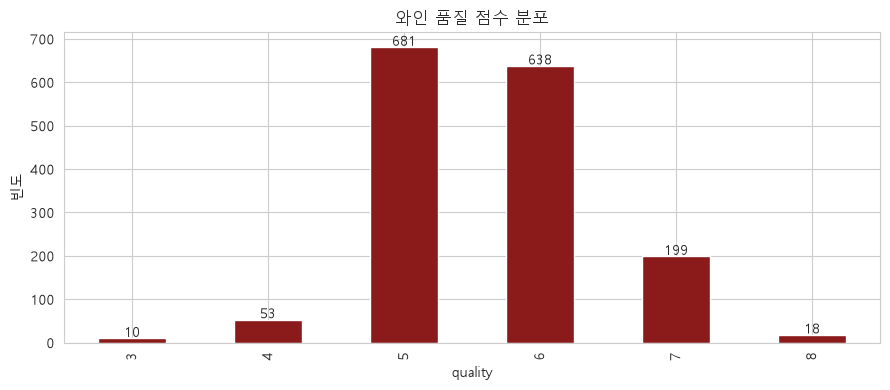

In [5]:
df['quality'].value_counts().sort_index().plot(kind='bar', figsize=(9,4), color='#8b1a1a')
plt.title('와인 품질 점수 분포')
plt.xlabel('quality')
plt.ylabel('빈도')
for i, v in enumerate(df['quality'].value_counts().sort_index().values):
    plt.text(i, v + 3, str(v), ha='center')
plt.tight_layout(); plt.show()

## 6) 변수 분포 (Histogram)

각 수치형 변수의 분포를 확인합니다. `residual sugar`, `chlorides`, `sulphates` 등은 오른쪽으로 긴 꼬리를 가진 **오른쪽 치우침(positive skew)** 분포를 보입니다.

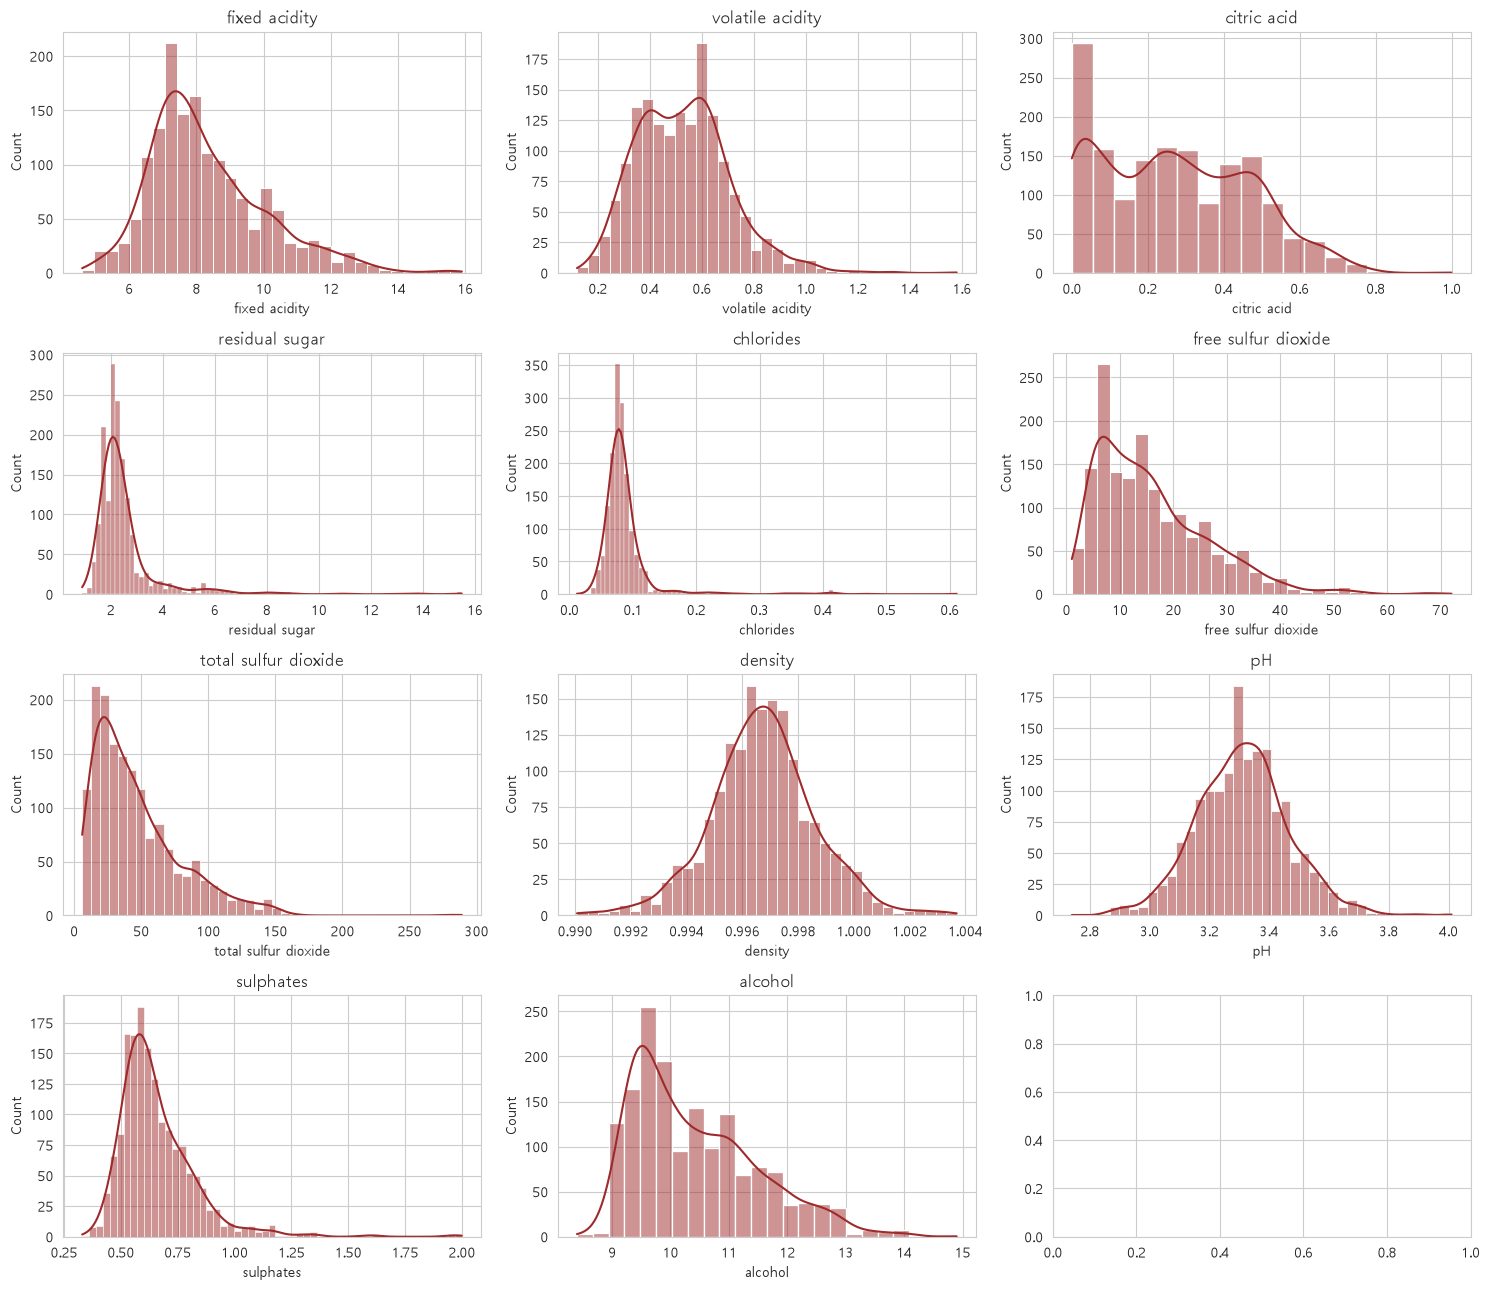

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(15, 13))
for ax, col in zip(axes.ravel(), df.columns[:-1]):
    sns.histplot(df[col], kde=True, ax=ax, color='#9e2a2b', edgecolor='white')
    ax.set_title(col)
plt.tight_layout(); plt.show()

## 7) 상관관계 분석

### 7-1) 상관 행렬 히트맵

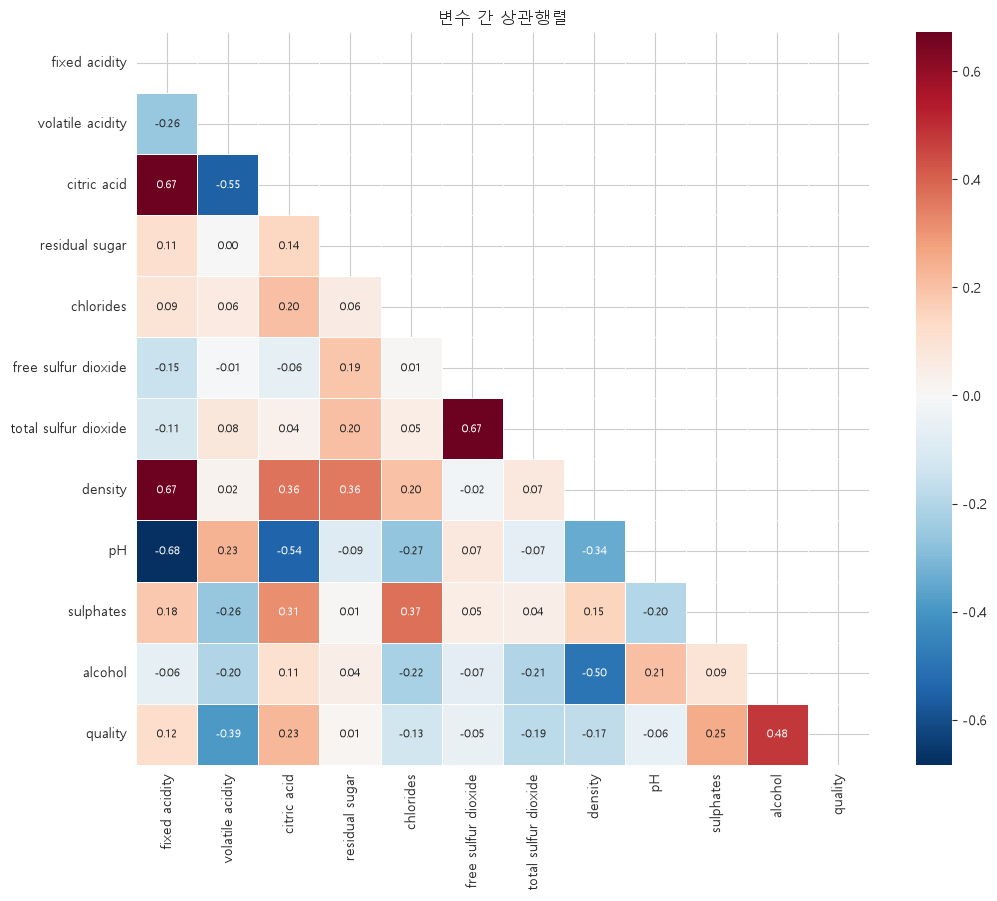

In [7]:
plt.figure(figsize=(11, 9))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, mask=mask,
            square=True, linewidths=0.5, annot_kws={'size': 8})
plt.title('변수 간 상관행렬')
plt.tight_layout(); plt.show()

### 7-2) quality와의 상관계수 (유의성 포함)

상관계수와 함께 **p-value**(귀무가설: 상관=0)를 계산합니다. p<0.05이면 유의한 상관으로 판단합니다.

In [8]:
from scipy import stats

results = []
for col in df.columns[:-1]:
    r, p = stats.pearsonr(df[col], df['quality'])
    results.append({'변수': col, '상관계수 r': round(r, 4), 'p-value': round(p, 6)})
corr_q = pd.DataFrame(results).sort_values('상관계수 r', ascending=False)
corr_q['유의성'] = corr_q['p-value'].apply(lambda p: '유의함' if p < 0.05 else '유의하지 않음')
corr_q

,변수,상관계수 r,p-value,유의성
10,alcohol,0.4762,0.000000,유의함
9,sulphates,0.2514,0.000000,유의함
2,citric acid,0.2264,0.000000,유의함
0,fixed acidity,0.1241,0.000001,유의함
3,residual sugar,0.0137,0.583218,유의하지 않음
5,free sulfur dioxide,-0.0507,0.042834,유의함
8,pH,-0.0577,0.020963,유의함
4,chlorides,-0.1289,0.000000,유의함
7,density,-0.1749,0.000000,유의함
6,total sulfur dioxide,-0.1851,0.000000,유의함


### 7-3) 해석

- **alcohol (r≈+0.48)**: 품질과 가장 강한 **양의 상관**. 알코올 도수가 높을수록 품질이 높다.
- **volatile acidity (r≈-0.39)**: 휘발성 산도(식초 냄새 유발)는 품질과 **음의 상관**. 높으면 품질이 낮아진다.
- **sulphates (r≈+0.25)**, **citric acid (r≈+0.23)** 도 품질과 양의 상관.

→ "알코올·황산염·구연산은 많을수록 좋고, 휘발성 산도·밀도·염화물은 적을수록 좋다"는 일반적인 상식과 일치합니다.

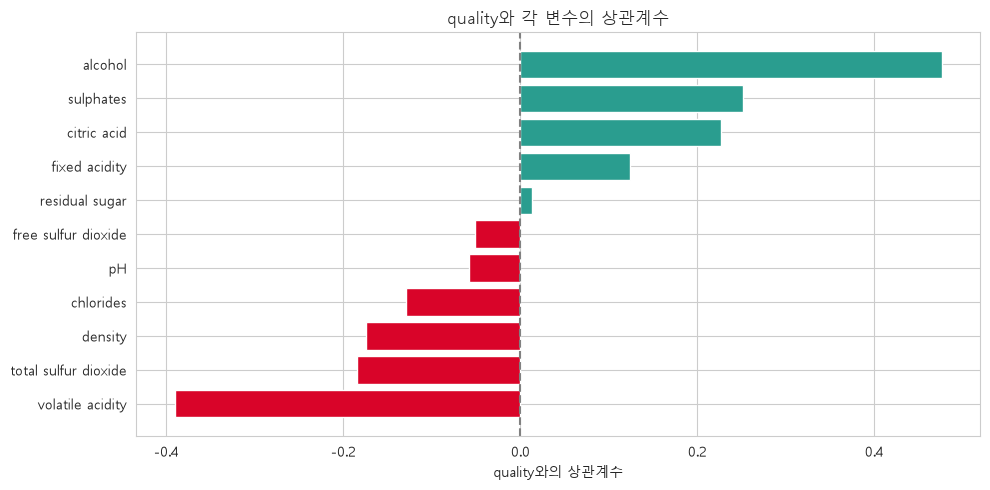

In [9]:
# 막대 그래프로 정리
plt.figure(figsize=(10, 5))
colors = ['#d90429' if r < 0 else '#2a9d8f' for r in corr_q['상관계수 r']]
plt.barh(corr_q['변수'], corr_q['상관계수 r'], color=colors)
plt.xlabel('quality와의 상관계수')
plt.title('quality와 각 변수의 상관계수')
plt.axvline(0, color='gray', ls='--')
plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

## 8) 품질 그룹별 비교

와인을 3그룹으로 나눕니다.
- **나쁨**: quality ≤ 4
- **보통**: quality 5~6
- **좋음**: quality ≥ 7

In [10]:
df['quality_group'] = pd.cut(df['quality'], bins=[0, 4, 6, 10], labels=['나쁨 (≤4)', '보통 (5~6)', '좋음 (≥7)'])
df['quality_group'].value_counts().sort_index().to_frame('와인 수')

,와인 수
quality_group,
나쁨 (≤4),63
보통 (5~6),1319
좋음 (≥7),217


In [11]:
# 그룹별 평균 비교 (핵심 변수 위주)
key_cols = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides',
            'density', 'pH', 'sulphates', 'alcohol']
df.groupby('quality_group', observed=True)[key_cols].mean().round(3).T

quality_group,나쁨 (≤4),보통 (5~6),좋음 (≥7)
fixed acidity,7.871,8.254,8.847
volatile acidity,0.724,0.539,0.406
citric acid,0.174,0.258,0.376
residual sugar,2.685,2.504,2.709
chlorides,0.096,0.089,0.076
density,0.997,0.997,0.996
pH,3.384,3.311,3.289
sulphates,0.592,0.647,0.743
alcohol,10.216,10.253,11.518


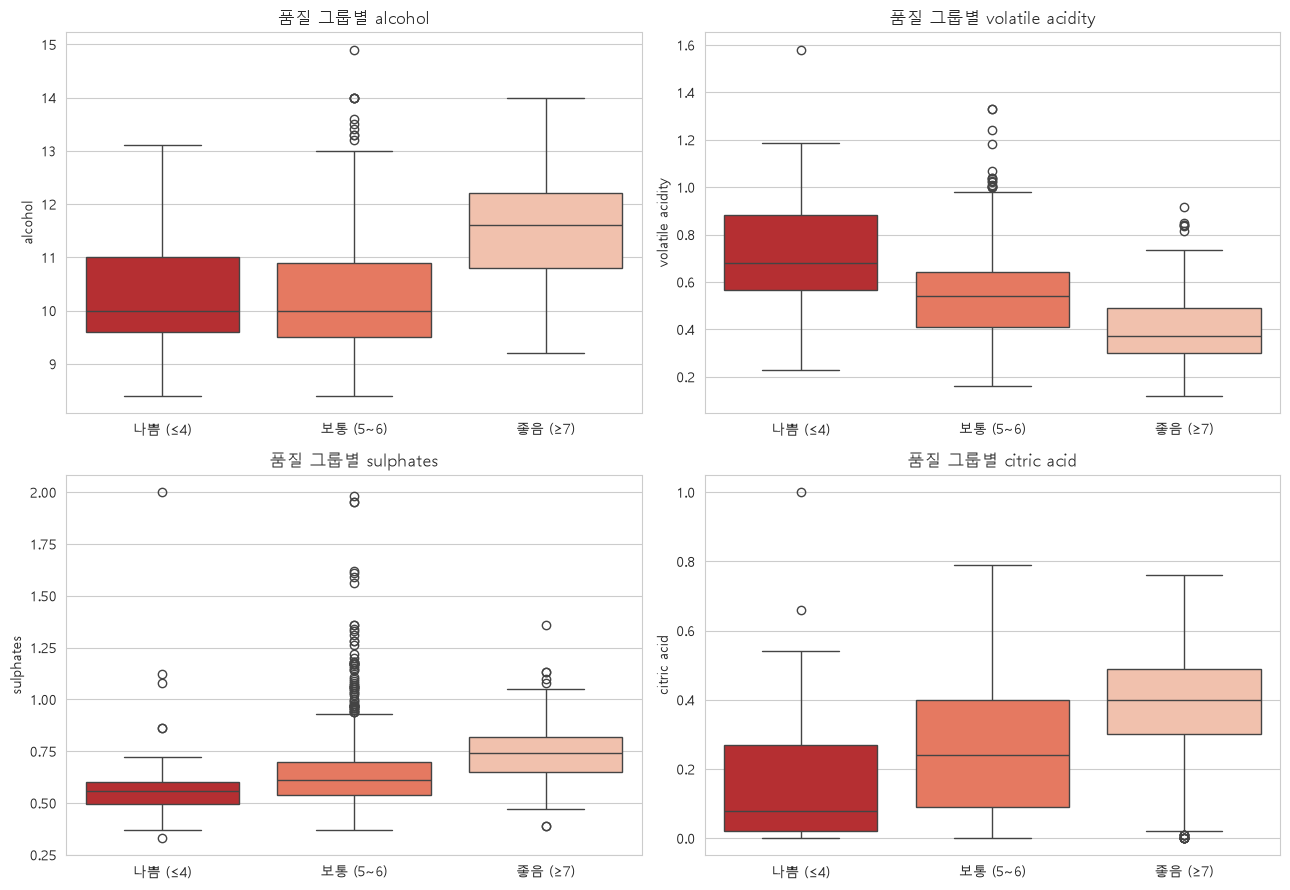

In [12]:
# 그룹별 상자그림 (alcohol, volatile acidity, sulphates, citric acid)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), ['alcohol', 'volatile acidity', 'sulphates', 'citric acid']):
    sns.boxplot(data=df, x='quality_group', y=col, ax=ax, order=['나쁨 (≤4)', '보통 (5~6)', '좋음 (≥7)'],
                palette='Reds_r')
    ax.set_title(f'품질 그룹별 {col}')
    ax.set_xlabel('')
plt.tight_layout(); plt.show()

### 8-1) 좋음 vs 나쁨 평균 차이 검정 (t-검정)

'좋음(≥7)'과 '나쁨(≤4)' 그룹의 평균 차이가 통계적으로 유의한지 **독립표본 t-검정**으로 확인합니다.

In [13]:
good = df[df['quality_group'] == '좋음 (≥7)']
bad = df[df['quality_group'] == '나쁨 (≤4)']

t_results = []
for col in key_cols:
    t, p = stats.ttest_ind(good[col], bad[col])
    t_results.append({'변수': col, 't-통계량': round(t, 3), 'p-value': round(p, 6),
                      '좋음 평균': round(good[col].mean(), 3), '나쁨 평균': round(bad[col].mean(), 3)})
t_df = pd.DataFrame(t_results).sort_values('p-value')
t_df['결론'] = t_df['p-value'].apply(lambda p: '유의한 차이' if p < 0.05 else '차이 없음')
t_df

,변수,t-통계량,p-value,좋음 평균,나쁨 평균,결론
1,volatile acidity,-12.847,0.000000,0.406,0.724,유의한 차이
2,citric acid,7.180,0.000000,0.376,0.174,유의한 차이
7,sulphates,6.659,0.000000,0.743,0.592,유의한 차이
8,alcohol,9.276,0.000000,11.518,10.216,유의한 차이
6,pH,-4.181,0.000039,3.289,3.384,유의한 차이
0,fixed acidity,3.537,0.000474,8.847,7.871,유의한 차이
4,chlorides,-3.186,0.001605,0.076,0.096,유의한 차이
5,density,-2.197,0.028821,0.996,0.997,유의한 차이
3,residual sugar,0.115,0.908718,2.709,2.685,차이 없음


## 9) 품질 vs 핵심 변수 산점도

알코올·휘발성 산도와 품질의 관계를 산점도로 확인합니다.

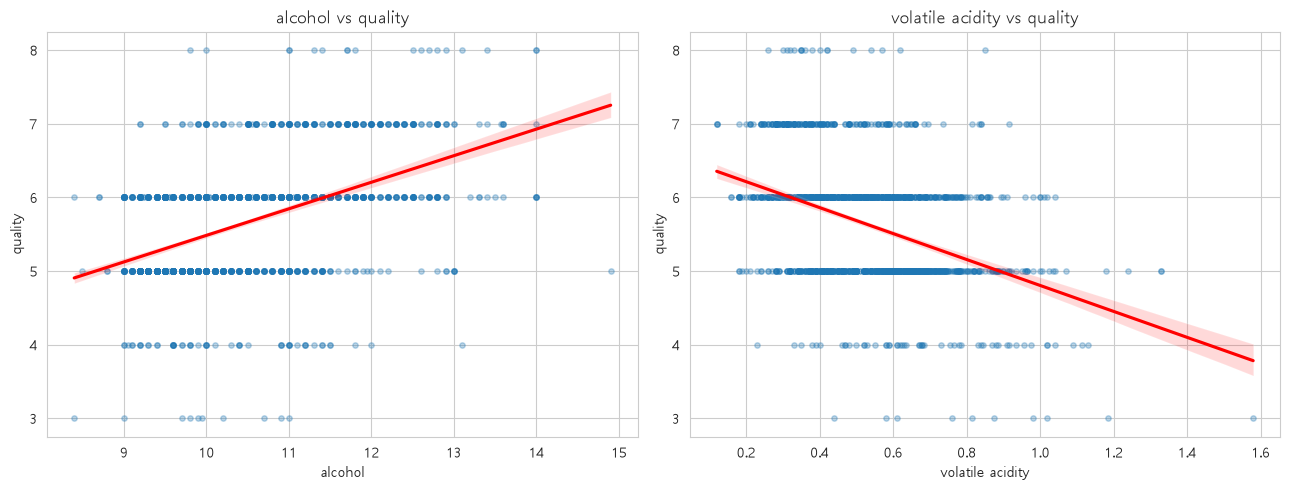

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col in zip(axes, ['alcohol', 'volatile acidity']):
    sns.regplot(data=df, x=col, y='quality', scatter_kws={'alpha': 0.3, 's': 15}, line_kws={'color': 'red'}, ax=ax)
    ax.set_title(f'{col} vs quality')
plt.tight_layout(); plt.show()

## 10) 머신러닝으로 품질 예측 (좋음 vs 그 외)

**RandomForest 분류기**로 좋은 와인(quality≥7) 여부를 예측하고, 어떤 변수가 중요한지 확인합니다.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

df_model = df.copy()
df_model['target'] = (df_model['quality'] >= 7).astype(int)   # 1 = 좋은 와인
X = df_model.drop(columns=['quality', 'quality_group', 'target'])
y = df_model['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print('정확도(Accuracy):', round(rf.score(X_test, y_test), 4))
print()
print(classification_report(y_test, rf.predict(X_test), target_names=['보통 이하', '좋은 와인'], zero_division=0))

정확도(Accuracy): 0.9292

              precision    recall  f1-score   support

       보통 이하       0.93      0.99      0.96       415
       좋은 와인       0.90      0.54      0.67        65

    accuracy                           0.93       480
   macro avg       0.91      0.76      0.82       480
weighted avg       0.93      0.93      0.92       480



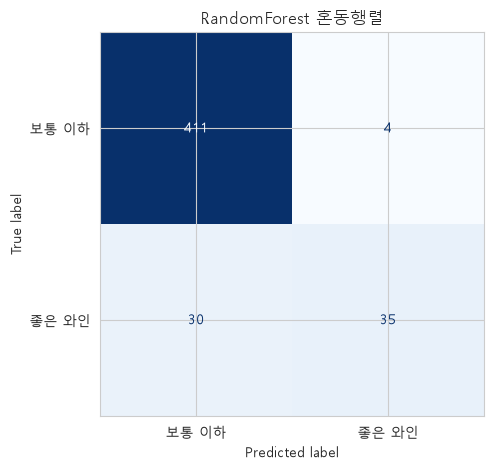

In [16]:
# 혼동 행렬
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test, display_labels=['보통 이하', '좋은 와인'],
                                      cmap='Blues', colorbar=False)
plt.title('RandomForest 혼동행렬')
plt.tight_layout(); plt.show()

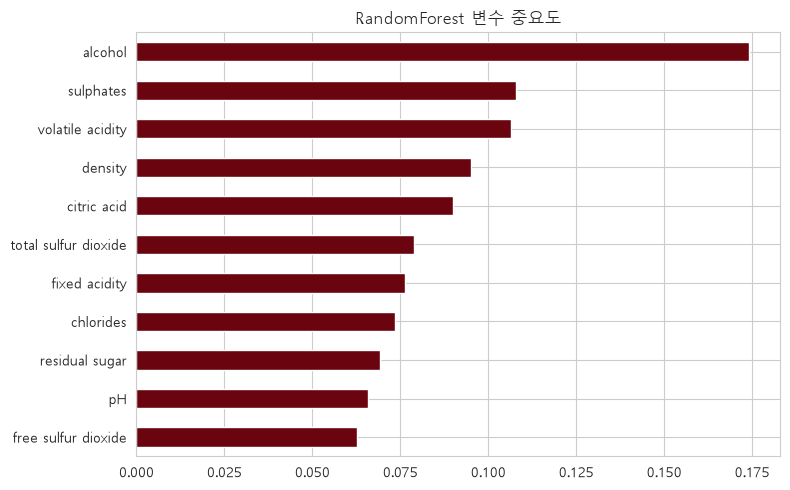

In [17]:
# 변수 중요도
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(8, 5))
imp.plot(kind='barh', color='#6a040f')
plt.title('RandomForest 변수 중요도')
plt.tight_layout(); plt.show()

## 11) 결론

1. 레드 와인 품질(3~8)은 **5~6점에 집중**되어 있고, 좋은(≥7) 와인은 약 13.6%뿐인 불균형 데이터입니다.
2. 품질과 가장 관계가 큰 변수는 **alcohol(양), volatile acidity(음)**이며, **sulphates, citric acid**도 유의한 양의 상관을 보입니다.
3. t-검정 결과 좋음/나쁨 그룹 간 대부분의 화학 특성이 유의한 차이를 보였습니다.
4. RandomForest로 좋은 와인 여부를 예측했을 때 변수 중요도에서도 **alcohol, volatile acidity, sulphates**가 핵심 변수로 나타나 상관분석 결과와 일치했습니다.
5. 화학 성분만으로 와인 품질을 정확히 예측하기는 어렵지만(정확도 약 0.85 이상은 아님), 일부 변수는 품질 판단의 유용한 지표가 됩니다.

In [18]:
print('분석 완료')

분석 완료
